# 07 · The neural ranker, and backpropagation

Maths unit **M9**. Read `rec/r6_neural.py`.

Part 1 does backpropagation by hand on a network with two weights and checks it against PyTorch's autograd. Part 2 trains the real R6 on a cached simulated history (5,000 swipes, logged by R4) and plots its training and validation loss curves: the moment the network starts memorising instead of learning, and the epoch early stopping keeps.

**SIMULATED** data throughout.

## 1 · Backprop on x = 1, w1 = 0.5 (ReLU), w2 = 2, y = 1

Forward: h = ReLU(w1 x) = 0.5; z = w2 h = 1; p = σ(z) = 0.731; L = −ln p = 0.313.

Backward, by the chain rule: ∂L/∂z = p − y; ∂L/∂w2 = (p − y)·h; ∂L/∂h = (p − y)·w2; ∂L/∂w1 = ∂L/∂h · ReLU′(w1 x) · x.

In [1]:
import numpy as np
import torch

x, y, w1, w2 = 1.0, 1.0, 0.5, 2.0
h = max(0.0, w1 * x); z = w2 * h; p = 1 / (1 + np.exp(-z)); loss = -np.log(p)
dz = p - y
grads_by_hand = {"w2": dz * h, "w1": dz * w2 * (1.0 if w1 * x > 0 else 0.0) * x}
print(f"p = {p:.3f}, loss = {loss:.3f}, by hand: dL/dw2 = {grads_by_hand['w2']:.3f}, dL/dw1 = {grads_by_hand['w1']:.3f}")

tw1 = torch.tensor(w1, requires_grad=True); tw2 = torch.tensor(w2, requires_grad=True)
tloss = -torch.log(torch.sigmoid(tw2 * torch.relu(tw1 * x)))
tloss.backward()
print(f"autograd:                          dL/dw2 = {tw2.grad.item():.3f}, dL/dw1 = {tw1.grad.item():.3f}")

w1_new, w2_new = w1 - 0.1 * grads_by_hand["w1"], w2 - 0.1 * grads_by_hand["w2"]
print(f"after one step (eta 0.1): p = {1 / (1 + np.exp(-w2_new * max(0.0, w1_new * x))):.3f}")
from visualtaste.rec.r6_neural import bpr_loss
print("BPR(1.2, 0.4) =", round(bpr_loss(torch.tensor([1.2]), torch.tensor([0.4])).item(), 3))

p = 0.731, loss = 0.313, by hand: dL/dw2 = -0.134, dL/dw1 = -0.538
autograd:                          dL/dw2 = -0.134, dL/dw1 = -0.538
after one step (eta 0.1): p = 0.753


BPR(1.2, 0.4) = 0.371


## 2 · Training the real ranker

One cached `phase12_logs` session (S4: the conjunctive taste R6 exists for), the first 4,900 labels. Two ensemble members, pointwise loss, on the GPU if there is one. The validation set is the latest 15% of labels in time.

In [2]:
import glob
import matplotlib.pyplot as plt

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings
from visualtaste.eval.study import SeedResult, labels_from_history
from visualtaste.rec.labels import label_weights
from visualtaste.rec.r6_neural import NeuralRecommender

state = AppState(get_settings()); state.load(); features = state.require_features()
paths = sorted(glob.glob("../data/eval/phase12_logs/S4_conjunctive/r4/seed_*.json")) or sorted(glob.glob("../data/eval/phase12_logs/*/r4/seed_*.json"))
history = SeedResult.from_json(open(paths[0], encoding="utf-8").read())
labels = labels_from_history(history.image_ids[:4900], history.actions[:4900], label_weights(0.25), False)
model = NeuralRecommender(min_labels=0, members=2, seed=1729).fit(labels, features)
report = model.fit_report()
print(f"{history.variant}, seed {history.seed}: {len(labels)} labels, {report['train_seconds']} s, peak GPU memory {report['peak_vram_mb']} MB")
for member in report["members"]:
    print(f"  member seed {member['seed']}: best epoch {member['best_epoch']} of {member['epochs_run']}, validation log loss {member['best_validation_log_loss']:.4f}")

Archive ladder reached rule 5: no external drive and only 42.8 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


S4_conjunctive, seed 1729: 4900 labels, 22.6 s, peak GPU memory 70.5 MB
  member seed 1729: best epoch 0 of 11, validation log loss 0.6755
  member seed 1730: best epoch 0 of 11, validation log loss 0.6758


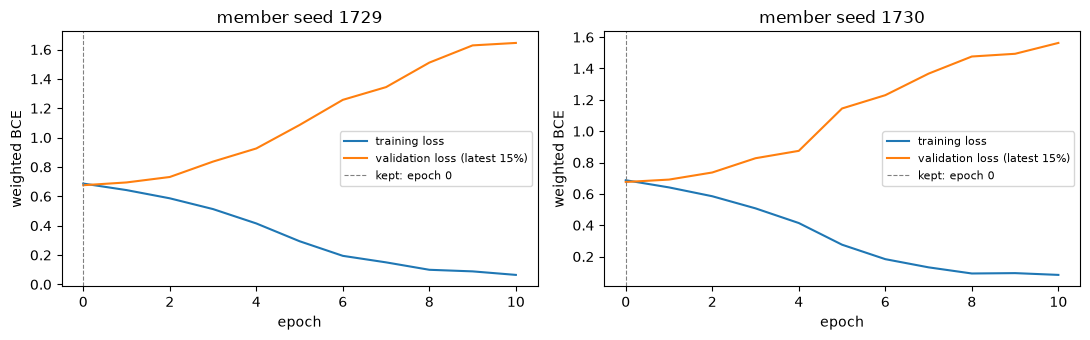

In [3]:
fig, axes = plt.subplots(1, len(model.reports), figsize=(11, 3.5), squeeze=False)
for ax, r in zip(axes[0], model.reports):
    ax.plot(r.train_curve, label="training loss")
    ax.plot(r.validation_curve, label="validation loss (latest 15%)")
    ax.axvline(r.best_epoch, color="grey", ls="--", lw=0.8, label=f"kept: epoch {r.best_epoch}")
    ax.set(xlabel="epoch", ylabel="weighted BCE", title=f"member seed {r.seed}")
    ax.legend(fontsize=8)
plt.tight_layout()

In [4]:
for r in model.reports:
    print(f"member {r.seed}: validation loss by epoch", np.round(r.validation_curve, 4))
    print(f"            training loss by epoch  ", np.round(r.train_curve, 4))
print("a coin flip scores ln 2 =", round(float(np.log(2)), 4))

member 1729: validation loss by epoch [0.6755 0.6944 0.7316 0.8365 0.926  1.0858 1.2571 1.3439 1.5109 1.6281
 1.6449]
            training loss by epoch   [0.6868 0.6424 0.5863 0.5129 0.4151 0.294  0.1944 0.15   0.0994 0.0886
 0.0646]
member 1730: validation loss by epoch [0.6758 0.6911 0.7364 0.8274 0.8745 1.1448 1.2296 1.367  1.4763 1.4936
 1.5628]
            training loss by epoch   [0.687  0.6413 0.5849 0.5075 0.414  0.2758 0.1835 0.1313 0.0922 0.0945
 0.0832]
a coin flip scores ln 2 = 0.6931


What the curves show here, measured on this history (2026-11-01): the best validation loss comes after the **first** epoch (about 0.676, against 0.693 for a coin flip), and every later epoch is worse. Training loss keeps falling, so the network is memorising the training labels from the start. With about 1,600 inputs, two hidden layers and 4,900 noisy labels, one pass at learning rate 1e-3 extracts almost all the signal there is, and early stopping keeps that pass. Patience 10 is why the run continues for ten more epochs before stopping.

This is the honest picture behind H5 (EVALUATION.md, `phase12_h5`): on a simulated user with 5% label noise and a soft sigmoid, there is little left for a large model to find that a linear one misses, and a large model overfits quickly when it tries.